In [1]:
import kagglehub
import pandas as pd
import os

# Download latest version
path = kagglehub.dataset_download("neelagiriaditya/ufc-datasets-1994-2025")

print("Path to dataset files:", path)

Path to dataset files: /home/taci/.cache/kagglehub/datasets/neelagiriaditya/ufc-datasets-1994-2025/versions/3


In [2]:
# Ver los archivos descargados en la ruta
archivos = os.listdir(path)
print("Archivos descargados:", archivos)

# Buscar el archivo .csv y mostrar su head
for archivo in archivos:
    if archivo.endswith('.csv'):
        ruta_csv = os.path.join(path, archivo)
        df = pd.read_csv(ruta_csv)
        display(df.head())
        break

Archivos descargados: ['event_details.csv', 'fighter_details.csv', 'fight_details.csv', 'UFC.csv']


,event_id,fight_id,date,location,winner,winner_id
0,6e380a4d73ab4f0e,5bcd8abf6da01dae,"September 06, 2025","Paris, Ile-de-France, France",Nassourdine Imavov,881bf86d4cba8578
1,6e380a4d73ab4f0e,d14fea43712707f0,"September 06, 2025","Paris, Ile-de-France, France",Benoit Saint Denis,c2299ec916bc7c56
2,6e380a4d73ab4f0e,0149e875b31e57f8,"September 06, 2025","Paris, Ile-de-France, France",Modestas Bukauskas,476fe566d2df676e
3,6e380a4d73ab4f0e,69b31593175f77ec,"September 06, 2025","Paris, Ile-de-France, France",Mason Jones,f6ad6a1e4d600e0d
4,6e380a4d73ab4f0e,a47123ae6e048f11,"September 06, 2025","Paris, Ile-de-France, France",Axel Sola,1d2d98ddd05b38fb


In [3]:
# Cargar específicamente UFC.csv
ruta_ufc = os.path.join(path, 'UFC.csv')
df_ufc = pd.read_csv(ruta_ufc)

# Crear un DataFrame con el tipo de dato y la cantidad de valores nulos por columna
resumen = pd.DataFrame({
    'Tipo de Dato': df_ufc.dtypes,
    'Datos Faltantes': df_ufc.isnull().sum()
})

# Guardar el resumen en un archivo CSV para poder verlo completo
resumen.to_csv('../data/resumen_ufc.csv')
print("Resumen guardado exitosamente en '../data/resumen_ufc.csv' en el directorio actual.")

display(resumen)

Resumen guardado exitosamente en 'resumen_ufc.csv' en el directorio actual.


,Tipo de Dato,Datos Faltantes
event_id,str,0
event_name,str,0
date,str,0
location,str,0
fight_id,str,0
...,...,...
b_td_avg_acc,int64,0
b_td_def,int64,0
b_sub_avg,float64,0
winner,str,147


# Exploratory Data Analysis

Esta sección analiza el dataset desde cuatro ángulos: contexto del evento, perfil físico de cada peleador, métricas de estilo de pelea y relaciones entre rincón rojo y azul.

La idea es entender qué variables describen mejor cada combate y qué patrones se asocian con el resultado final.

In [4]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 16
plt.rcParams["axes.labelsize"] = 12

# Copia de trabajo
eda = df_ufc.copy()

# Fechas y variables derivadas básicas
for col in ["date", "r_dob", "b_dob"]:
    if col in eda.columns:
        eda[col] = pd.to_datetime(eda[col], errors="coerce")

if "date" in eda.columns:
    eda["year"] = eda["date"].dt.year
    eda["month"] = eda["date"].dt.to_period("M").astype(str)

if {"r_dob", "b_dob", "date"}.issubset(eda.columns):
    eda["r_age"] = (eda["date"] - eda["r_dob"]).dt.days / 365.25
    eda["b_age"] = (eda["date"] - eda["b_dob"]).dt.days / 365.25
    eda["age_diff_rb"] = eda["r_age"] - eda["b_age"]

numeric_cols = eda.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = eda.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print(f"Filas: {eda.shape[0]:,} | Columnas: {eda.shape[1]:,}")
print(f"Numéricas: {len(numeric_cols)} | Categóricas/bool: {len(cat_cols)}")
print("Nulos totales:", int(eda.isna().sum().sum()))

display(
    pd.DataFrame({
        "tipo": eda.dtypes.astype(str),
        "nulos": eda.isna().sum(),
        "pct_nulos": (eda.isna().mean() * 100).round(2)
    }).sort_values("pct_nulos", ascending=False).head(20)
)

Filas: 8,337 | Columnas: 129
Numéricas: 108 | Categóricas/bool: 18
Nulos totales: 31136


/tmp/ipykernel_327501/196921551.py:29: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = eda.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


,tipo,nulos,pct_nulos
b_ground_acc,float64,3816,45.77
b_td_acc,float64,3126,37.50
r_ground_acc,float64,2956,35.46
r_td_acc,float64,2686,32.22
b_nick_name,str,2388,28.64
r_nick_name,str,2328,27.92
b_clinch_acc,float64,2042,24.49
r_clinch_acc,float64,2003,24.03
r_leg_acc,float64,1584,19.00
b_leg_acc,float64,1568,18.81


## Filtrado a peleas masculinas

Primero construimos un dataset solo con peleas masculinas. La división nos permite identificar y excluir las categorías femeninas.


Total peleas: 8,337
Peleas masculinas: 7,471
Peleas femeninas: 866


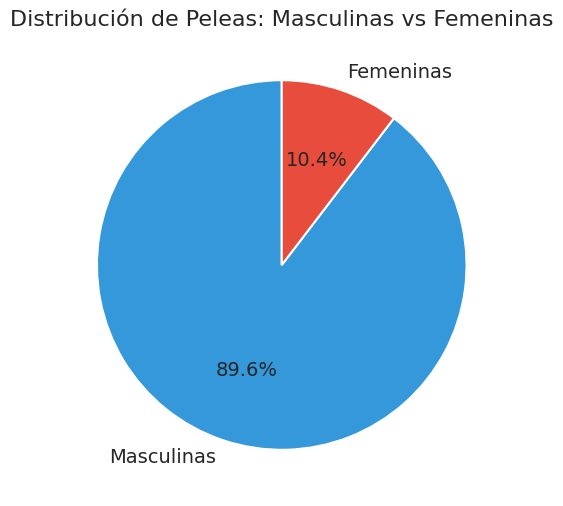

,event_id,event_name,date,location,fight_id,division,title_fight,method,finish_round,match_time_sec,...,b_splm,b_str_acc,b_sapm,b_str_def,b_td_avg,b_td_avg_acc,b_td_def,b_sub_avg,winner,winner_id
0,6e380a4d73ab4f0e,UFC Fight Night: Imavov vs. Borralho,2025/09/06,"Paris, Ile-de-France, France",d14fea43712707f0,lightweight,0,Submission,2,176,...,3.84,57,4.16,60,0.00,0,84,0.0,Benoit Saint Denis,c2299ec916bc7c56
1,6e380a4d73ab4f0e,UFC Fight Night: Imavov vs. Borralho,2025/09/06,"Paris, Ile-de-France, France",5bcd8abf6da01dae,middleweight,0,Decision - Unanimous,5,300,...,3.44,56,2.50,60,1.28,48,76,0.4,Nassourdine Imavov,881bf86d4cba8578
2,6e380a4d73ab4f0e,UFC Fight Night: Imavov vs. Borralho,2025/09/06,"Paris, Ile-de-France, France",0149e875b31e57f8,light heavyweight,0,KO/TKO,1,300,...,2.50,45,3.04,43,1.43,18,35,1.3,Modestas Bukauskas,476fe566d2df676e
3,6e380a4d73ab4f0e,UFC Fight Night: Imavov vs. Borralho,2025/09/06,"Paris, Ile-de-France, France",69b31593175f77ec,lightweight,0,KO/TKO,2,198,...,5.71,41,4.47,50,4.17,55,81,0.2,Mason Jones,f6ad6a1e4d600e0d
4,6e380a4d73ab4f0e,UFC Fight Night: Imavov vs. Borralho,2025/09/06,"Paris, Ile-de-France, France",a47123ae6e048f11,welterweight,0,KO/TKO,3,122,...,4.71,40,7.15,47,0.00,0,47,0.0,Axel Sola,1d2d98ddd05b38fb
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8332,a6a9ab5a824e8f66,UFC 2: No Way Out,1994/03/11,"Denver, Colorado, USA",3b020d4914b44fc8,open weight,0,KO/TKO,1,170,...,0.00,0,0.00,0,0.00,0,0,0.0,Orlando Wiet,a6c2f5381d575920
8333,a6a9ab5a824e8f66,UFC 2: No Way Out,1994/03/11,"Denver, Colorado, USA",ccee020be2e8d9f6,open weight,0,KO/TKO,1,733,...,0.00,0,0.00,0,0.00,0,0,0.0,Johnny Rhodes,319fa1bd3176bded
8334,a6a9ab5a824e8f66,UFC 2: No Way Out,1994/03/11,"Denver, Colorado, USA",d917c8c7461b9831,open weight,0,Submission,1,292,...,0.00,0,0.00,0,0.00,0,0,0.0,Frank Hamaker,c3c23c99477c041b
8335,a6a9ab5a824e8f66,UFC 2: No Way Out,1994/03/11,"Denver, Colorado, USA",4b9ae533ccb3fcdf,open weight,0,Submission,1,58,...,0.00,0,0.00,0,0.00,0,0,0.0,Patrick Smith,46c8ec317aff28ac


In [5]:
import matplotlib.pyplot as plt

# Filtrar solo peleas masculinas por division
eda_male = df_ufc.copy()

if "division" in eda_male.columns:
    female_mask = eda_male["division"].astype(str).str.contains("women", case=False, na=False)
    eda_male = eda_male.loc[~female_mask].copy()

total_peleas = len(df_ufc)
peleas_masculinas = len(eda_male)
peleas_femeninas = total_peleas - peleas_masculinas

print(f"Total peleas: {total_peleas:,}")
print(f"Peleas masculinas: {peleas_masculinas:,}")
print(f"Peleas femeninas: {peleas_femeninas:,}")

plt.figure(figsize=(6, 6))
labels = ['Masculinas', 'Femeninas']
sizes = [peleas_masculinas, peleas_femeninas]
colors = ['#3498db', '#e74c3c']

plt.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90, textprops={'fontsize': 14})
plt.title('Distribución de Peleas: Masculinas vs Femeninas', fontsize=16)
plt.show()

# Usar este dataset como base del EDA
eda = eda_male.copy()
if 'date' in eda.columns:
    eda['year'] = pd.to_datetime(eda['date'], errors='coerce').dt.year
eda

## Filtramos las Peleas Modernas
Este recorte temporal permite trabajar con una etapa más representativa de la UFC moderna.

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------
# 1. Preparación base
# -----------------------------

df_cut = eda.copy()

df_cut['date'] = pd.to_datetime(df_cut['date'], errors='coerce')
df_cut = df_cut.dropna(subset=['date']).copy()
df_cut['year'] = df_cut['date'].dt.year

# -----------------------------
# 2. Cantidad de peleas por corte temporal
# -----------------------------

cuts = [1994, 2001, 2010]

cut_counts = []

for cut in cuts:
    cut_counts.append({
        'Corte temporal': f"{cut}+",
        'Cantidad de peleas': len(df_cut[df_cut['year'] >= cut])
    })

cut_counts = pd.DataFrame(cut_counts)

# Marcar el corte elegido
cut_counts['Tipo'] = cut_counts['Corte temporal'].apply(
    lambda x: 'Corte elegido' if x == '2010+' else 'Referencia'
)

print(cut_counts)

  Corte temporal  Cantidad de peleas           Tipo
0          1994+                7471     Referencia
1          2001+                7204     Referencia
2          2010+                6206  Corte elegido


In [7]:
base_count = len(df_cut[df_cut['year'] >= 1994])
cut_counts['Porcentaje conservado'] = (
    cut_counts['Cantidad de peleas'] / base_count * 100
).round(1)

print(cut_counts)

  Corte temporal  Cantidad de peleas           Tipo  Porcentaje conservado
0          1994+                7471     Referencia                  100.0
1          2001+                7204     Referencia                   96.4
2          2010+                6206  Corte elegido                   83.1


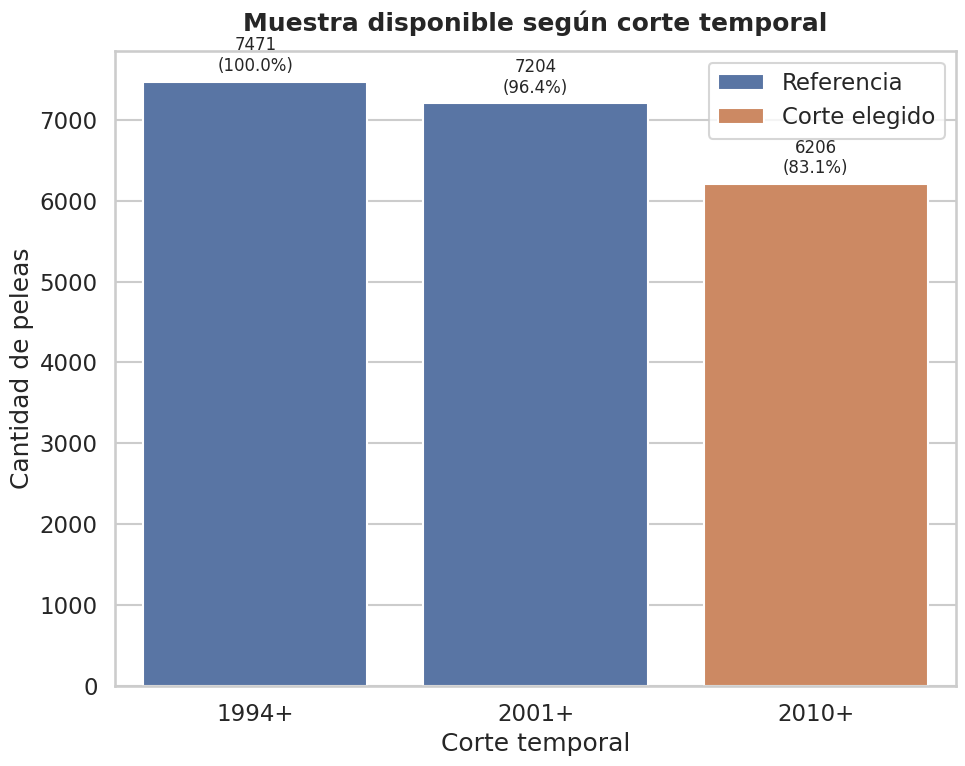

In [8]:
sns.set_theme(style="whitegrid", context="talk")

plt.figure(figsize=(10, 8))

ax = sns.barplot(
    data=cut_counts,
    x='Corte temporal',
    y='Cantidad de peleas',
    hue='Tipo',
    dodge=False
)

plt.title(
    "Muestra disponible según corte temporal",
    fontsize=18,
    fontweight="bold",
    pad=15
)

plt.xlabel("Corte temporal")
plt.ylabel("Cantidad de peleas")
plt.legend(title="")

for i, row in cut_counts.iterrows():
    ax.text(
        i,
        row['Cantidad de peleas'] + 80,
        f"{int(row['Cantidad de peleas'])}\n({row['Porcentaje conservado']}%)",
        ha='center',
        va='bottom',
        fontsize=12
    )

plt.tight_layout()
plt.show()

In [ ]:
for cut in [2001, 2005, 2010, 2015]:
    temp = eda[eda['year'] >= cut].copy()
    temp_male = temp[
        ~temp['division'].str.contains("women", case=False, na=False)
    ].copy()

    print(f"\nDesde {cut}")
    print("Total peleas:", len(temp))
    print("Peleas masculinas:", len(temp_male))
    print("Años:", temp['year'].min(), "-", temp['year'].max())
    print("Divisiones:", temp_male['division'].nunique())

df_podado = eda[eda['year'] >= 2010].copy()

KeyError: 'year'

## Diagnóstico general del dataset

Primero revisamos cobertura temporal, faltantes y distribución de las variables categóricas principales.

Tipos de datos actualizados en el dataset 'eda' (Muestra de las primeras 15 columnas):


event_id                     str
event_name                   str
date              datetime64[us]
location                     str
fight_id                     str
division                     str
title_fight                int64
method                       str
finish_round               int64
match_time_sec             int64
total_rounds             float64
referee                      str
r_name                       str
r_id                         str
r_kd                     float64
dtype: object

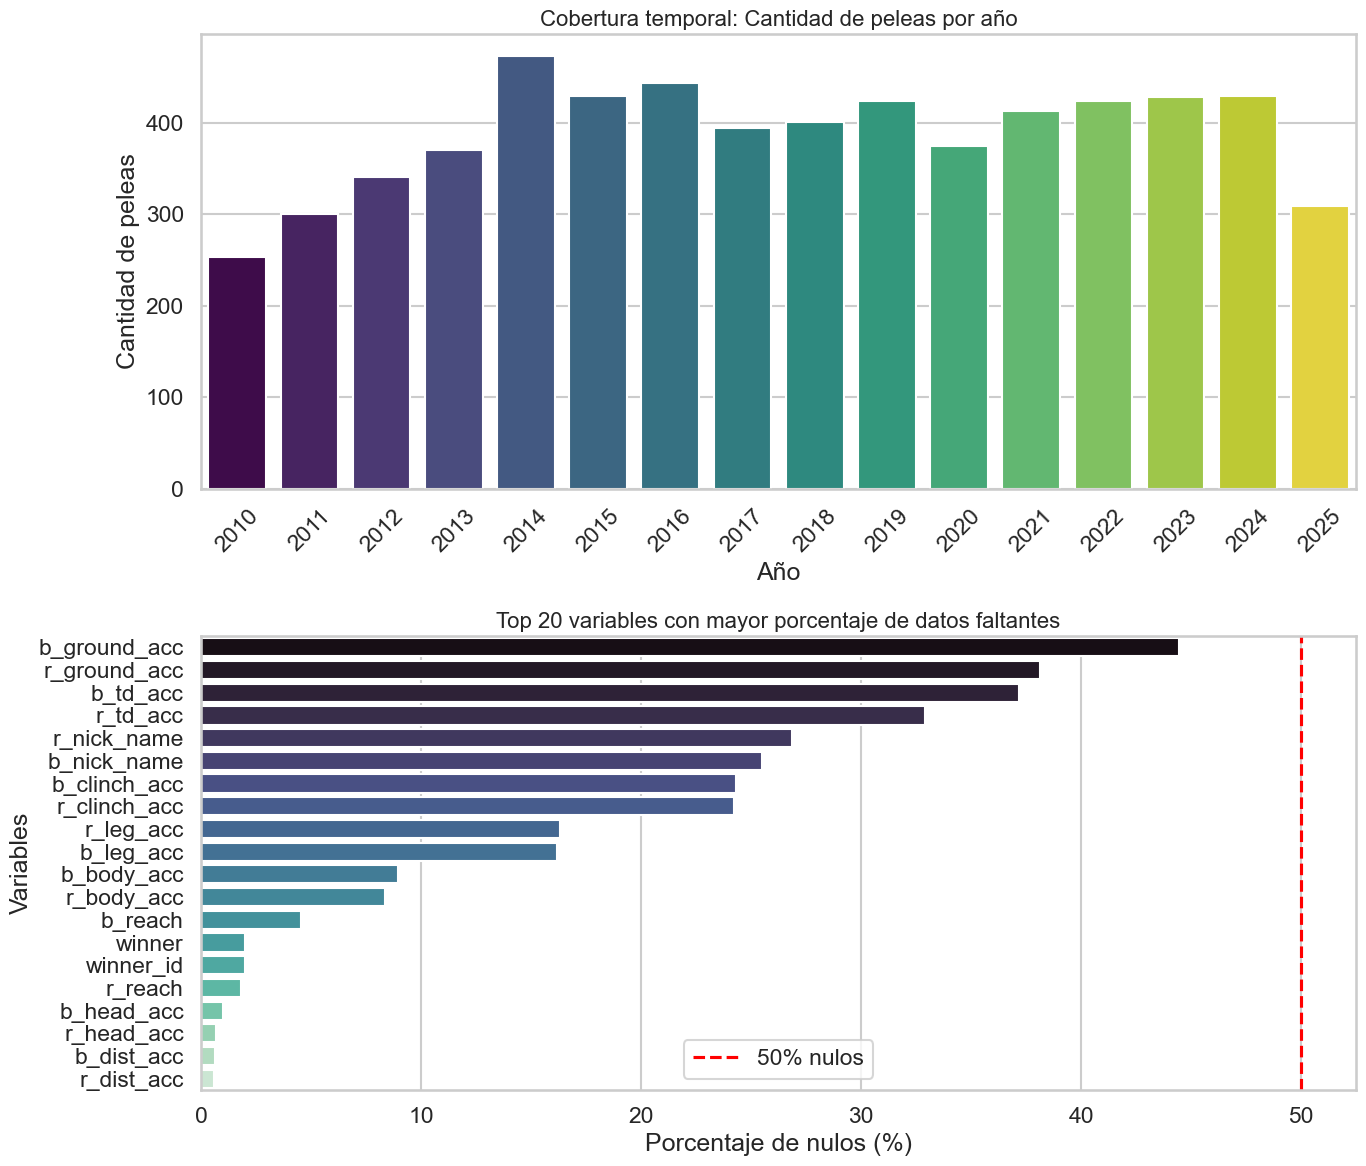

Cantidad de valores únicos en las variables categóricas principales:


/var/folders/cs/b6gncpdn4g30nvxwwbqh1wlr0000gn/T/ipykernel_29923/4086076553.py:45: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols_info = df_podado.select_dtypes(include=['object', 'category']).nunique().sort_values(ascending=False)


fight_id       6206
b_id           1752
b_name         1751
r_id           1492
r_name         1491
winner_id      1394
winner         1393
b_nick_name    1057
r_nick_name     914
event_id        604
dtype: int64

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd


for col in ["date", "r_dob", "b_dob"]:
    if col in df_podado.columns:
        df_podado[col] = pd.to_datetime(df_podado[col], errors='coerce')

if 'date' in df_podado.columns:
    df_podado['year'] = df_podado['date'].dt.year
    df_podado['month'] = df_podado['date'].dt.to_period("M").astype(str)

# Imprimimos los tipos de dato ya corregidos
print("Tipos de datos actualizados en el dataset 'eda' (Muestra de las primeras 15 columnas):")
display(df_podado.dtypes.head(15))

fig, axes = plt.subplots(2, 1, figsize=(14, 12))

# 1. Cobertura temporal (Peleas por año)
if 'year' in df_podado.columns:
    sns.countplot(data=df_podado, x='year', hue='year', ax=axes[0], palette="viridis", legend=False)
    axes[0].set_title("Cobertura temporal: Cantidad de peleas por año", fontsize=16)
    axes[0].set_xlabel("Año")
    axes[0].set_ylabel("Cantidad de peleas")
    axes[0].tick_params(axis='x', rotation=45)

# 2. Análisis de datos faltantes (Gráfico de atributos con más nulos)
nulos_porcentaje = (df_podado.isna().mean() * 100).sort_values(ascending=False)
nulos_porcentaje = nulos_porcentaje[nulos_porcentaje > 0] # Solo las columnas que tienen nulos

if not nulos_porcentaje.empty:
    sns.barplot(x=nulos_porcentaje.values[:20], y=nulos_porcentaje.index[:20], hue=nulos_porcentaje.index[:20], ax=axes[1], palette="mako", legend=False)
    axes[1].set_title("Top 20 variables con mayor porcentaje de datos faltantes", fontsize=16)
    axes[1].set_xlabel("Porcentaje de nulos (%)")
    axes[1].set_ylabel("Variables")
    # Línea de referencia en 50%
    axes[1].axvline(50, color='red', linestyle='--', label='50% nulos')
    axes[1].legend()

plt.tight_layout()
plt.show()

# 3. Distribución de variables categóricas
cat_cols_info = df_podado.select_dtypes(include=['object', 'category']).nunique().sort_values(ascending=False)
print("Cantidad de valores únicos en las variables categóricas principales:")
display(cat_cols_info.head(10))

## Evento y combate

Acá miramos la estructura de cada pelea: división, método de cierre, round de finalización y duración total.

/var/folders/cs/b6gncpdn4g30nvxwwbqh1wlr0000gn/T/ipykernel_29923/3128275295.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=data, y="division", order=division_order, ax=axes[0, 0], palette="crest")
/var/folders/cs/b6gncpdn4g30nvxwwbqh1wlr0000gn/T/ipykernel_29923/3128275295.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=data, y="method", order=method_order, ax=axes[0, 1], palette="mako")


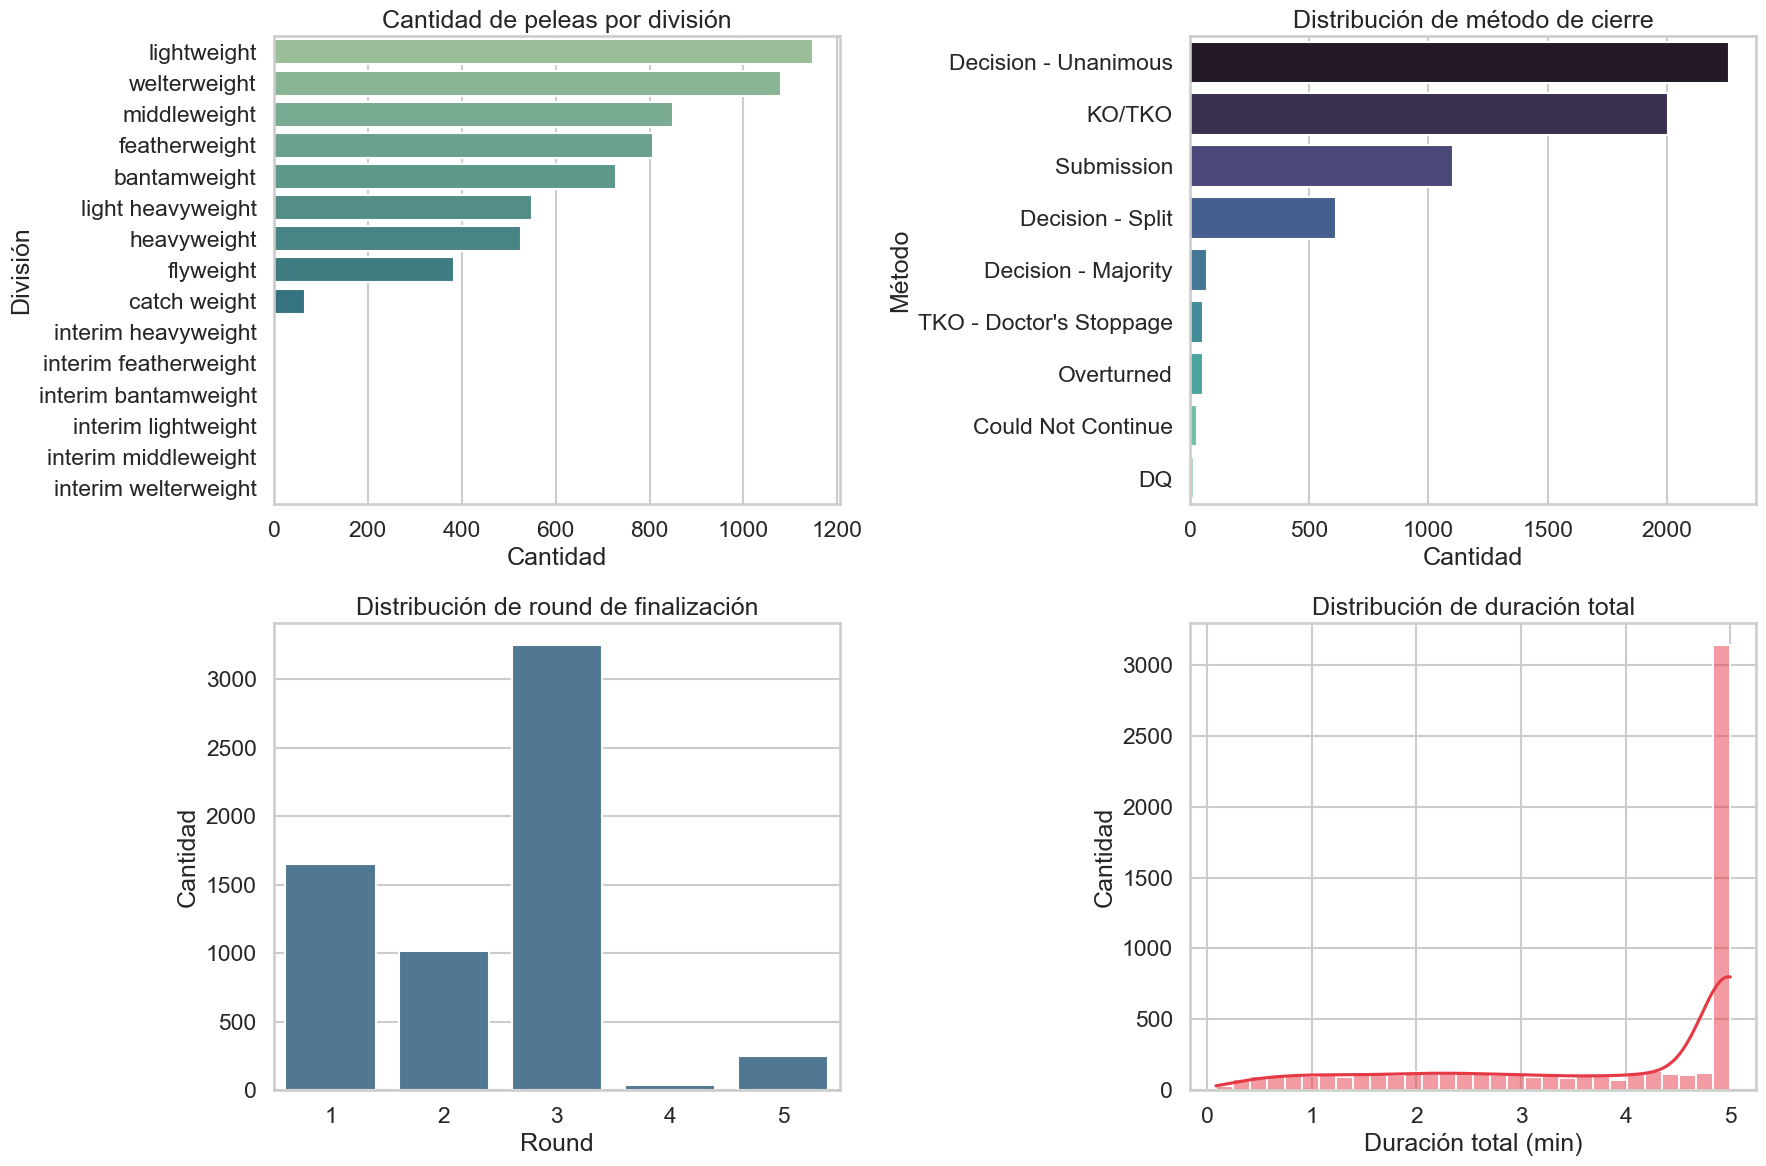

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Usar dataset podado
data = df_podado.copy()

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# 1) Cantidad de peleas por division
division_order = data["division"].astype(str).value_counts().index[:15]
sns.countplot(data=data, y="division", order=division_order, ax=axes[0, 0], palette="crest")
axes[0, 0].set_title("Cantidad de peleas por división")
axes[0, 0].set_xlabel("Cantidad")
axes[0, 0].set_ylabel("División")

# 2) Distribucion de metodo de cierre
method_order = data["method"].astype(str).value_counts().index[:15]
sns.countplot(data=data, y="method", order=method_order, ax=axes[0, 1], palette="mako")
axes[0, 1].set_title("Distribución de método de cierre")
axes[0, 1].set_xlabel("Cantidad")
axes[0, 1].set_ylabel("Método")

# 3) Distribucion de round de finalizacion
sns.countplot(data=data, x="finish_round", ax=axes[1, 0], color="#457b9d")
axes[1, 0].set_title("Distribución de round de finalización")
axes[1, 0].set_xlabel("Round")
axes[1, 0].set_ylabel("Cantidad")

# 4) Distribucion de duracion total en minutos
data["match_time_min"] = data["match_time_sec"] / 60
sns.histplot(data=data, x="match_time_min", bins=30, kde=True, ax=axes[1, 1], color="#e63946")
axes[1, 1].set_title("Distribución de duración total")
axes[1, 1].set_xlabel("Duración total (min)")
axes[1, 1].set_ylabel("Cantidad")

plt.tight_layout()
plt.show()

In [ ]:
# Guardar df_podado para el siguiente notebook
df_podado.to_csv('../data/df_podado.csv', index=False)
print("df_podado guardado en data/df_podado.csv exitosamente.")